# **Conformal Prediction para Dataset: King County House Sales (2014–2015)**

**Objetivo.** Tomar un modelo de regresión cualquiera y convertir sus predicciones puntuales en **intervalos con cobertura garantizada**, y luego comprobar con datos que la garantía se cumple.

**Qué hace este notebook**

1. Revisa y limpia los datos.
2. Entrena un Random Forest para predecir el precio de venta de casas.
3. Muestra por qué un intervalo "ingenuo" falla.
4. Implementa **split conformal prediction a mano** (son unas pocas líneas).
5. Verifica la cobertura empírica contra la cobertura pedida.
6. Muestra una limitación (ancho constante) y cómo la resuelve una variante, **CQR**.

Todo es reproducible: semilla fija, dataset incluido en el repositorio y versiones fijadas en `requirements.txt`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import train_test_split

SEED = 42       # semilla fija para reproducibilidad
ALPHA = 0.10    # error tolerado -> cobertura objetivo = 1 - ALPHA = 90%

FIG_DIR = Path("figures/king_county")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Estilo de las gráficas
AZUL, AZUL_CLARO, NARANJA = "#2a78d6", "#9ec5f4", "#eb6834"
TEXTO, TEXTO_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "text.color": TEXTO,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TEXTO_2, "axes.edgecolor": REJILLA,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Problema y datos

Usamos **King County House Sales**: ventas reales de casas en el condado de King (Seattle y alrededores) entre mayo de 2014 y mayo de 2015. A diferencia de California Housing, cada fila es **una venta de una casa individual** y la variable objetivo es su **precio de venta**, que trabajamos en miles de USD.

Es el mismo tipo de pregunta del inicio de la exposición: *el modelo dice que la casa vale X, pero ¿en qué rango esperamos que esté el precio real?*

In [2]:
crudo = pd.read_csv("data/kc_house_data.csv", dtype={"id": str, "zipcode": str})
crudo["fecha"] = pd.to_datetime(crudo["date"].str[:8], format="%Y%m%d")

print(f"{len(crudo)} ventas, del {crudo['fecha'].min():%Y-%m-%d} al {crudo['fecha'].max():%Y-%m-%d}")
crudo.head()

21613 ventas, del 2014-05-02 al 2015-05-27


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,fecha
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,1180,0,1955,0,98178,47.5112,-122.257,1340,5650,2014-10-13
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639,2014-12-09
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,770,0,1933,0,98028,47.7379,-122.233,2720,8062,2015-02-25
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,1050,910,1965,0,98136,47.5208,-122.393,1360,5000,2014-12-09
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,1680,0,1987,0,98074,47.6168,-122.045,1800,7503,2015-02-18


### Revisión de calidad

Antes de dividir revisamos que los datos tengan sentido: faltantes, duplicados y valores imposibles.

In [3]:
revision = pd.Series({
    "Valores faltantes": int(crudo.isna().sum().sum()),
    "Filas duplicadas": int(crudo.duplicated().sum()),
    "Casas vendidas más de una vez (id repetido)": int(crudo["id"].duplicated().sum()),
    "Casas con 0 habitaciones": int((crudo["bedrooms"] == 0).sum()),
    "Casas con 0 baños": int((crudo["bathrooms"] == 0).sum()),
    "Casas con 30 o más habitaciones": int((crudo["bedrooms"] >= 30).sum()),
    "Ventas por encima de 2 millones de USD": int((crudo["price"] > 2_000_000).sum()),
}, name="casos")
revision.to_frame()

,casos
Valores faltantes,0
Filas duplicadas,0
Casas vendidas más de una vez (id repetido),177
Casas con 0 habitaciones,13
Casas con 0 baños,10
Casas con 30 o más habitaciones,1
Ventas por encima de 2 millones de USD,198


In [4]:
crudo.nlargest(3, "bedrooms")[["bedrooms", "bathrooms", "sqft_living", "price"]]

,bedrooms,bathrooms,sqft_living,price
15870,33,1.75,1620,640000.0
8757,11,3.00,3000,520000.0
13314,10,5.25,4590,1148000.0


### **Limpieza de los datos**

Tres decisiones, todas tomadas **antes** de dividir porque ninguna aprende parámetros de los datos (no hay medias, escalas ni modelos involucrados):

1. **Una venta por casa.** Si la misma casa queda en entrenamiento y en prueba, el modelo ya la "conoce" y la evaluación se infla. Nos quedamos con la venta más reciente.
2. **Quitar registros imposibles:** casas con 0 habitaciones o 0 baños, y la casa con 33 habitaciones en 1.620 pies², casi seguro un error de digitación.
3. **No quitar las casas caras.** Son casos difíciles, pero reales. Si las borramos la cobertura se ve mejor, pero sería una garantía sobre datos que ya no representan la realidad.

**¿Y estandarizar?** No hace falta: el Random Forest divide por umbrales, así que la escala de las variables no cambia sus decisiones. Si se usara un modelo sensible a la escala (regresión regularizada, KNN, redes), el escalador debe ajustarse **solo con entrenamiento**, idealmente dentro de un `Pipeline`, para que calibración y prueba se transformen exactamente igual que los datos nuevos.

In [5]:
df = crudo.sort_values("fecha").drop_duplicates("id", keep="last")
imposibles = (df["bedrooms"] == 0) | (df["bathrooms"] == 0) | (df["bedrooms"] >= 30)
df = df[~imposibles]

print(f"Ventas originales:                {len(crudo)}")
print(f"Ventas repetidas descartadas:     {crudo['id'].duplicated().sum()}")
print(f"Registros imposibles descartados: {imposibles.sum()}")
print(f"Casas para el experimento:        {len(df)}")

Ventas originales:                21613
Ventas repetidas descartadas:     177
Registros imposibles descartados: 17
Casas para el experimento:        21419


### Variables

Dejamos fuera `id` y `date`, que no describen la casa, y `zipcode`: es un código, no una cantidad, y la ubicación ya está en `lat` y `long`.

In [6]:
variables = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront", "view",
             "condition", "grade", "sqft_above", "sqft_basement", "yr_built", "yr_renovated",
             "lat", "long", "sqft_living15", "sqft_lot15"]

X = df[variables].astype(float)
y = df["price"] / 1000          # miles de USD

print(f"{len(df)} casas, {X.shape[1]} variables predictoras")
print(f"Precio: mediana {y.median():.0f} mil USD, máximo {y.max():.0f} mil USD")

21419 casas, 17 variables predictoras
Precio: mediana 450 mil USD, máximo 7700 mil USD


## 2. División de los datos

Conformal prediction necesita **tres** conjuntos, no dos:

| Conjunto | Para qué | Proporción |
|---|---|---|
| Entrenamiento | Ajustar el modelo | 60% |
| **Calibración** | Medir qué tan grandes son los errores del modelo en datos que no vio | 20% |
| Prueba | Comprobar que la cobertura se cumple | 20% |

In [7]:
X_train, X_resto, y_train, y_resto = train_test_split(X, y, test_size=0.40, random_state=SEED)
X_cal, X_test, y_cal, y_test = train_test_split(X_resto, y_resto, test_size=0.50, random_state=SEED)

print(f"Entrenamiento: {len(X_train)} | Calibración: {len(X_cal)} | Prueba: {len(X_test)}")

Entrenamiento: 12851 | Calibración: 4284 | Prueba: 4284


## 3. El modelo

Un Random Forest sin ajuste fino. Conformal prediction lo trata como **caja negra**: lo único que necesita es su método `predict`.

In [8]:
from sklearn.metrics import mean_absolute_error, r2_score

modelo = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)
modelo.fit(X_train, y_train)

pred_train = modelo.predict(X_train)
pred_cal = modelo.predict(X_cal)
pred_test = modelo.predict(X_test)

desempeno = pd.DataFrame({
    "¿el modelo lo vio al entrenar?": ["sí", "no", "no"],
    "error absoluto medio (miles USD)": [mean_absolute_error(y_train, pred_train),
                                         mean_absolute_error(y_cal, pred_cal),
                                         mean_absolute_error(y_test, pred_test)],
    "R²": [r2_score(y_train, pred_train), r2_score(y_cal, pred_cal), r2_score(y_test, pred_test)],
}, index=["Entrenamiento", "Calibración", "Prueba"])
desempeno.round({"error absoluto medio (miles USD)": 1, "R²": 3})

,¿el modelo lo vio al entrenar?,error absoluto medio (miles USD),R²
Entrenamiento,sí,25.7,0.983
Calibración,no,68.9,0.874
Prueba,no,71.8,0.866


El modelo es bueno (R² alto en prueba), pero en entrenamiento se equivoca **mucho menos** que en datos nuevos: ya conoce esas respuestas. En cambio, calibración y prueba tienen errores parecidos entre sí, porque ninguno de los dos se usó para entrenar. Esa es justamente la idea de Conformal Prediction: medir los errores en calibración para anticipar los errores con datos nuevos.

Y lo que el modelo entrega es solo un número por casa:

In [9]:
i = 0   # primera casa del conjunto de prueba
print(X_test.iloc[i][["bedrooms", "bathrooms", "sqft_living", "grade", "yr_built"]].to_string())
print(f"\nPredicción del modelo: {pred_test[i]:.1f} mil USD")
print(f"Valor real:            {y_test.iloc[i]:.1f} mil USD")
print("\n¿Qué tan seguro está el modelo de su predicción? Con un solo número, no lo sabemos.")

bedrooms          4.00
bathrooms         1.75
sqft_living    1840.00
grade             7.00
yr_built       1958.00

Predicción del modelo: 467.4 mil USD
Valor real:            404.0 mil USD

¿Qué tan seguro está el modelo de su predicción? Con un solo número, no lo sabemos.


## 4. El intento ingenuo (y por qué falla)

Una idea natural: mirar los errores del modelo en los datos de **entrenamiento** y usar su percentil 90 como margen.

El problema es que el modelo ya vio esos datos, así que sus errores ahí son mucho más pequeños que los que cometerá con datos nuevos.

In [10]:
errores_train = np.abs(y_train - pred_train).to_numpy()
errores_cal = np.abs(y_cal - pred_cal).to_numpy()
errores_test = np.abs(y_test - pred_test).to_numpy()

margen_ingenuo = np.quantile(errores_train, 1 - ALPHA)
cobertura_ingenua = np.mean(errores_test <= margen_ingenuo)

print(f"Margen ingenuo:      ±{margen_ingenuo:.1f} mil USD")
print(f"Cobertura pedida:    {1 - ALPHA:.0%}")
print(f"Cobertura obtenida:  {cobertura_ingenua:.1%}")

Margen ingenuo:      ±56.7 mil USD
Cobertura pedida:    90%
Cobertura obtenida:  63.4%


### ¿Por qué falla?

Comparamos los errores del modelo en los tres conjuntos y cuántas casas quedarían dentro del margen ingenuo en cada uno.

El intervalo promete 90% y queda muy por debajo. Por eso existe el conjunto de calibración.

In [11]:
conjuntos = {"Entrenamiento": errores_train, "Calibración": errores_cal, "Prueba": errores_test}

diagnostico = pd.DataFrame({
    "¿el modelo lo vio?": ["sí", "no", "no"],
    "error mediano": [np.median(e) for e in conjuntos.values()],
    "percentil 90 del error": [np.quantile(e, 1 - ALPHA) for e in conjuntos.values()],
    "dentro de ± margen ingenuo": [f"{np.mean(e <= margen_ingenuo):.1%}" for e in conjuntos.values()],
}, index=conjuntos.keys())
diagnostico.round(1)

,¿el modelo lo vio?,error mediano,percentil 90 del error,dentro de ± margen ingenuo
Entrenamiento,sí,14.4,56.7,90.0%
Calibración,no,39.2,147.6,62.8%
Prueba,no,38.9,160.9,63.4%


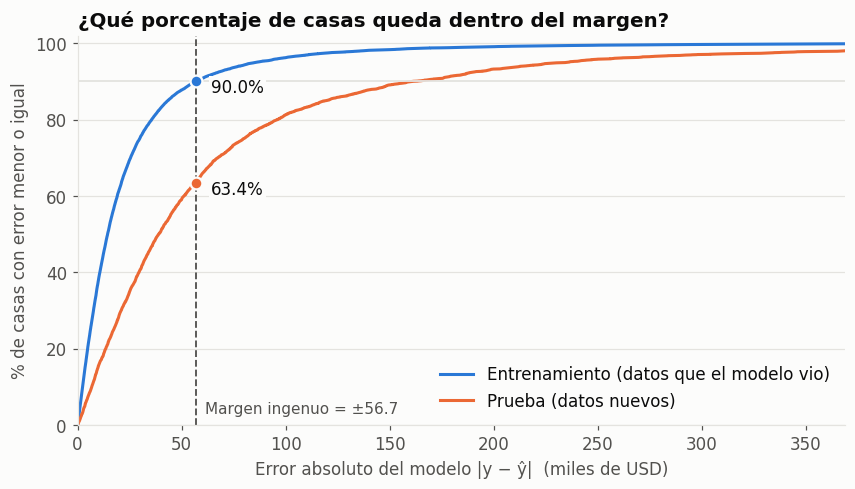

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.6))
limite_x = np.quantile(errores_test, 0.98)
for nombre, errores, color in [("Entrenamiento (datos que el modelo vio)", errores_train, AZUL),
                               ("Prueba (datos nuevos)", errores_test, NARANJA)]:
    x = np.sort(errores)
    ax.plot(x, np.arange(1, len(x) + 1) / len(x) * 100, color=color, linewidth=2, label=nombre)
    pct = np.mean(errores <= margen_ingenuo) * 100
    ax.scatter([margen_ingenuo], [pct], s=60, color=color, edgecolor=FONDO, linewidth=1.5, zorder=4)
    ax.annotate(f"{pct:.1f}%", (margen_ingenuo, pct), xytext=(10, -4), textcoords="offset points",
                va="center", color=TEXTO, fontsize=11,
                bbox=dict(facecolor=FONDO, edgecolor="none", pad=1.5))

ax.axvline(margen_ingenuo, color=TEXTO_2, linewidth=1.2, linestyle="--")
ax.annotate(f"Margen ingenuo = ±{margen_ingenuo:.1f}", (margen_ingenuo, 3), xytext=(6, 0),
            textcoords="offset points", color=TEXTO_2, fontsize=10)
ax.axhline((1 - ALPHA) * 100, color=REJILLA, linewidth=1.2)
ax.set_xlim(0, limite_x)
ax.set_ylim(0, 102)
ax.set_title("¿Qué porcentaje de casas queda dentro del margen?")
ax.set_xlabel("Error absoluto del modelo |y − ŷ|  (miles de USD)")
ax.set_ylabel("% de casas con error menor o igual")
ax.legend(loc="lower right")
fig.savefig(FIG_DIR / "00_intento_ingenuo.png")
plt.show()

**Cómo leer la gráfica:** cada curva dice qué porcentaje de casas tiene un error menor o igual a cada valor. En la línea punteada (el margen ingenuo), la curva de entrenamiento llega al 90%: ahí el margen funciona, porque se calculó con esos mismos datos. La curva de prueba queda muy por debajo: con casas nuevas el modelo se equivoca más y el margen se queda corto.

Fíjate en la tabla: **calibración y prueba tienen errores parecidos entre sí**, y mucho más grandes que en entrenamiento. Por eso Conformal Prediction mide los errores en calibración: se parecen a los que el modelo cometerá con datos nuevos.

El problema no se arregla con un mejor modelo: cualquier modelo se equivoca menos en los datos con los que aprendió. Se arregla midiendo los errores en datos que no vio.


## **5. Split (Conformal Prediction a mano)**

Tres pasos:

1. **Puntaje de no conformidad** en cada dato de calibración: $s_i = |y_i - \hat{y}_i|$
2. **Umbral** $\hat{q}$: el puntaje que ocupa la posición $\lceil (n+1)(1-\alpha) \rceil$ al ordenarlos de menor a mayor
3. **Intervalo** para un dato nuevo: $[\hat{y} - \hat{q},\ \hat{y} + \hat{q}]$

In [13]:
def cuantil_conformal(puntajes, alpha):
    # Umbral q̂: el puntaje en la posición ceil((n+1)(1-alpha)) de menor a mayor.
    puntajes = np.sort(np.asarray(puntajes))
    n = len(puntajes)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    if k > n:                      # muy pocos datos de calibración para ese alpha
        return np.inf
    return puntajes[k - 1]


# Paso 1: puntajes de no conformidad en calibración
puntajes = np.abs(y_cal - pred_cal).to_numpy()

# Paso 2: umbral
q_hat = cuantil_conformal(puntajes, ALPHA)

# Paso 3: intervalos para los datos de prueba
inferior = pred_test - q_hat
superior = pred_test + q_hat

n = len(puntajes)
print(f"n de calibración = {n}  ->  posición {int(np.ceil((n + 1) * (1 - ALPHA)))} de {n}")
print(f"q̂ = {q_hat:.1f} mil USD  ->  intervalo = predicción ± {q_hat:.1f}")

n de calibración = 4284  ->  posición 3857 de 4284
q̂ = 147.9 mil USD  ->  intervalo = predicción ± 147.9


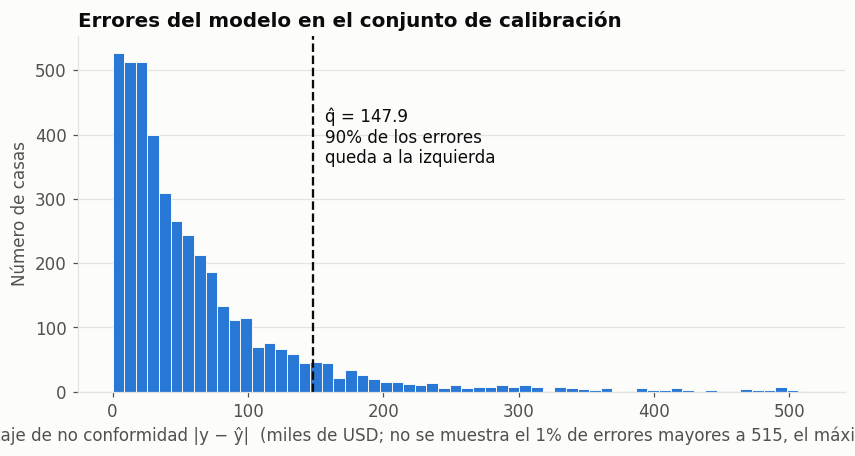

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.2))
limite = np.quantile(puntajes, 0.99)    # la cola es muy larga: se muestra hasta el percentil 99
ax.hist(puntajes[puntajes <= limite], bins=60, color=AZUL, edgecolor=FONDO, linewidth=0.6)
ax.axvline(q_hat, color=TEXTO, linewidth=1.5, linestyle="--")
ax.annotate(f"q̂ = {q_hat:.1f}\n{1 - ALPHA:.0%} de los errores\nqueda a la izquierda",
            xy=(q_hat, ax.get_ylim()[1] * 0.80), xytext=(8, 0), textcoords="offset points",
            va="top", color=TEXTO)
ax.set_title("Errores del modelo en el conjunto de calibración")
ax.set_xlabel(f"Puntaje de no conformidad |y − ŷ|  (miles de USD; no se muestra el 1% de errores "
              f"mayores a {limite:.0f}, el máximo es {puntajes.max():.0f})")
ax.set_ylabel("Número de casas")
fig.savefig(FIG_DIR / "01_puntajes_calibracion.png")
plt.show()

Predicción del modelo:   464.4 mil USD
Intervalo al 90%:        [464.4 − 148.6,  464.4 + 148.6]  =  [315.8, 613.0] mil USD
Valor real:              404.0 mil USD  ->  dentro del intervalo ✓

### Paso 2 de cerca: el ranking de errores

Ordenamos los errores de calibración de menor a mayor y miramos alrededor de la posición $k$. El umbral $\hat{q}$ no es una fórmula complicada: es simplemente el error que ocupa esa posición.

In [15]:
orden = np.sort(puntajes)
k = int(np.ceil((n + 1) * (1 - ALPHA)))

ranking = pd.DataFrame({
    "posición": np.arange(1, n + 1),
    "error (miles USD)": orden,
    "% de errores hasta aquí": np.arange(1, n + 1) / n * 100,
}).set_index("posición")

filas = [1, 2, 3, k - 2, k - 1, k, k + 1, k + 2, n - 1, n]
tabla = ranking.loc[filas].round(1)
tabla["nota"] = ""
tabla.loc[1, "nota"] = "error más pequeño"
tabla.loc[k, "nota"] = "← q̂ (posición k)"
tabla.loc[n, "nota"] = "error más grande"
tabla

,error (miles USD),% de errores hasta aquí,nota
posición,,,
1,0.0,0.0,error más pequeño
2,0.1,0.0,
3,0.1,0.1,
3855,147.5,90.0,
3856,147.6,90.0,
3857,147.9,90.0,← q̂ (posición k)
3858,148.0,90.1,
3859,148.4,90.1,
4283,1450.1,100.0,


### ¿Qué hace el "+1"?

La casa nueva es la número $n+1$ del ranking: por eso la fórmula usa $(n+1)$ y no $n$. Con muchos datos casi no cambia nada, pero con pocos datos de calibración la diferencia importa. Y si hay muy pocos, el método devuelve un intervalo infinito en vez de prometer algo que no puede garantizar.

In [16]:
filas = []
for n_cal in [5, 10, 20, 50, 100, n]:
    k_con = int(np.ceil((n_cal + 1) * (1 - ALPHA)))
    k_sin = int(np.ceil(n_cal * (1 - ALPHA)))
    filas.append({
        "datos de calibración (n)": n_cal,
        "posición k con +1": k_con if k_con <= n_cal else f"{k_con} > n → intervalo infinito",
        "posición sin +1": k_sin,
        "cobertura garantizada": f"{min(k_con, n_cal + 1) / (n_cal + 1):.1%}" if k_con <= n_cal else "100% (intervalo infinito)",
    })
pd.DataFrame(filas).set_index("datos de calibración (n)")

,posición k con +1,posición sin +1,cobertura garantizada
datos de calibración (n),,,
5,6 > n → intervalo infinito,5,100% (intervalo infinito)
10,10,9,90.9%
20,19,18,90.5%
50,46,45,90.2%
100,91,90,90.1%
4284,3857,3856,90.0%


### Paso 3 aplicado: la casa de ejemplo

Volvemos a la casa de la sección 3. Antes el modelo solo daba un número; ahora da un rango.

In [17]:
i = 0
print(f"Predicción del modelo:   {pred_test[i]:.1f} mil USD")
print(f"Intervalo al {1 - ALPHA:.0%}:        [{pred_test[i]:.1f} − {q_hat:.1f},  {pred_test[i]:.1f} + {q_hat:.1f}]"
      f"  =  [{inferior[i]:.1f}, {superior[i]:.1f}] mil USD")
print(f"Valor real:              {y_test.iloc[i]:.1f} mil USD  ->  "
      f"{'dentro del intervalo ✓' if inferior[i] <= y_test.iloc[i] <= superior[i] else 'fuera del intervalo ✗'}")

Predicción del modelo:   467.4 mil USD
Intervalo al 90%:        [467.4 − 147.9,  467.4 + 147.9]  =  [319.5, 615.3] mil USD
Valor real:              404.0 mil USD  ->  dentro del intervalo ✓


## 6. Resultado: predicciones con intervalo

Hasta aquí calculamos un solo número, $\hat{q}$. Ahora lo aplicamos a **todas** las casas de prueba: las casas que hacen el papel de "datos nuevos", porque el modelo no las usó para entrenar ni para calibrar.

Ya no decimos solo "el precio es X": damos un rango en el que esperamos el precio real 9 de cada 10 veces.

En la tabla, cada fila es una casa de prueba:

| Columna | Qué es |
|---|---|
| `valor_real` | El precio real, que el modelo no conoce |
| `prediccion` | Lo que predijo el Random Forest |
| `inferior`, `superior` | Los límites del intervalo: predicción − $\hat{q}$ y predicción + $\hat{q}$ |
| `ancho` | superior − inferior |
| `cubierto` | `True` si el precio real quedó dentro del intervalo |

In [18]:
resultado = pd.DataFrame({
    "valor_real": y_test.to_numpy(),
    "prediccion": pred_test,
    "inferior": inferior,
    "superior": superior,
})
resultado["ancho"] = resultado["superior"] - resultado["inferior"]
resultado["cubierto"] = resultado["valor_real"].between(resultado["inferior"], resultado["superior"])
resultado.head(8).round(1)

,valor_real,prediccion,inferior,superior,ancho,cubierto
0,404.0,467.4,319.5,615.3,295.8,True
1,435.0,427.1,279.2,575.0,295.8,True
2,125.0,259.9,112.0,407.8,295.8,True
3,780.0,663.8,515.9,811.7,295.8,True
4,385.0,328.1,180.2,476.0,295.8,True
5,729.0,811.8,663.9,959.7,295.8,True
6,276.8,261.6,113.7,409.5,295.8,True
7,238.0,246.5,98.6,394.4,295.8,True


**Cómo leer una fila:** en la primera, el modelo predice un precio y el intervalo va de predicción − $\hat{q}$ a predicción + $\hat{q}$. El precio real cae dentro, así que `cubierto` es `True`. Es la misma casa de ejemplo de las secciones 3 y 5.

Fíjate en la columna `ancho`: **es igual en todas las filas** ($2\hat{q}$). Split conformal le pone el mismo margen a cualquier casa, sea barata o cara. Volveremos a esto en la sección 8.

### El conteo completo

La tabla muestra solo 8 filas. Contemos todas las casas de prueba:

In [19]:
total = len(resultado)
dentro = resultado["cubierto"].sum()
fuera = total - dentro

print(f"Casas de prueba:       {total}")
print(f"Dentro del intervalo:  {dentro}  ({dentro / total:.1%})")
print(f"Fuera del intervalo:   {fuera}  ({fuera / total:.1%})")
print(f"Cobertura pedida:      {1 - ALPHA:.0%}")

Casas de prueba:       4284
Dentro del intervalo:  3801  (88.7%)
Fuera del intervalo:   483  (11.3%)
Cobertura pedida:      90%


Más o menos 9 de cada 10 casas quedan dentro, como se pidió. En la sección 7 vemos por qué el número exacto puede quedar un poco por encima o por debajo del 90%.

### ¿Qué casas quedan fuera?

El método acepta equivocarse el 10% de las veces, pero esos fallos no se reparten al azar:

In [20]:
fallos = resultado[~resultado["cubierto"]].copy()
fallos["fuera por"] = np.where(fallos["valor_real"] > fallos["superior"],
                               fallos["valor_real"] - fallos["superior"],
                               fallos["inferior"] - fallos["valor_real"])

umbral_caro = resultado["prediccion"].quantile(0.75)
print(f"Predicción mediana de todas las casas:   {resultado['prediccion'].median():.1f} mil USD")
print(f"Predicción mediana de las que fallan:    {fallos['prediccion'].median():.1f} mil USD")
print(f"Fallos en el 25% de casas más caras:     {(fallos['prediccion'] > umbral_caro).mean():.0%}")

fallos.sort_values("fuera por", ascending=False).head(5).round(1)

Predicción mediana de todas las casas:   459.0 mil USD
Predicción mediana de las que fallan:    855.6 mil USD
Fallos en el 25% de casas más caras:     73%


,valor_real,prediccion,inferior,superior,ancho,cubierto,fuera por
1413,7700.0,4720.0,4572.0,4867.9,295.8,False,2832.1
4195,800.0,3517.5,3369.5,3665.4,295.8,False,2569.5
3173,2888.0,5053.5,4905.5,5201.4,295.8,False,2017.5
1547,2415.0,4116.7,3968.7,4264.6,295.8,False,1553.7
3726,1325.0,2691.1,2543.2,2839.0,295.8,False,1218.2


Los fallos se concentran en las casas más caras: ahí el modelo se equivoca más, pero el intervalo es igual de ancho que para las baratas. Si los fallos se repartieran al azar, solo el 25% caería en ese grupo. La tabla muestra los 5 fallos más grandes, con cuánto se salió el precio real del intervalo.

### La gráfica

Para verlo de forma visual tomamos 60 casas de prueba al azar y las ordenamos por precio predicho, de menor a mayor:

- **Barra azul clara:** el intervalo de cada casa.
- **Raya azul:** la predicción del modelo, en el centro de la barra.
- **Punto negro:** el precio real, cuando cae dentro del intervalo.
- **X naranja:** el precio real, cuando cae fuera.

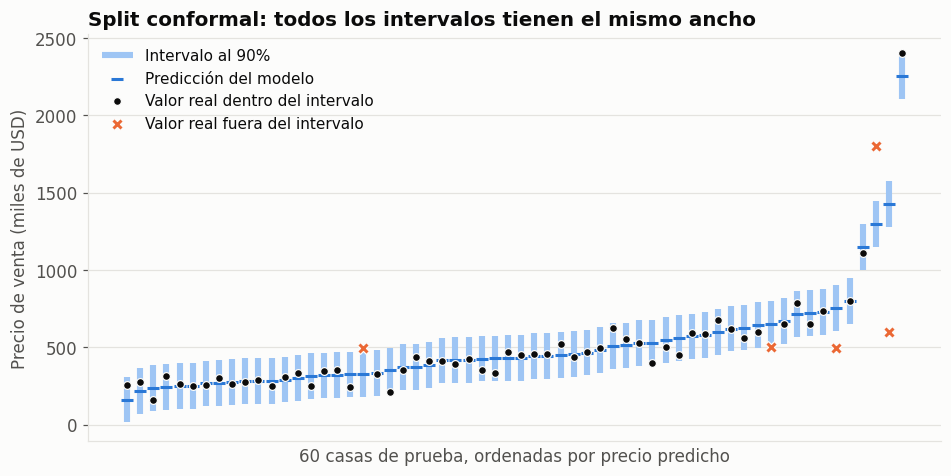

En esta muestra: 55 de 60 valores reales dentro del intervalo


In [21]:
def grafica_intervalos(res, titulo, archivo, etiqueta_pred="Predicción del modelo", n_muestra=60):
    # Muestra aleatoria de casas de prueba, ordenados por predicción.
    m = res.sample(n_muestra, random_state=SEED).sort_values("prediccion").reset_index(drop=True)
    dentro, fuera = m[m["cubierto"]], m[~m["cubierto"]]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.vlines(m.index, m["inferior"], m["superior"], color=AZUL_CLARO, linewidth=4,
              label=f"Intervalo al {1 - ALPHA:.0%}")
    ax.scatter(m.index, m["prediccion"], marker="_", s=70, color=AZUL, linewidth=2,
               label=etiqueta_pred, zorder=3)
    ax.scatter(dentro.index, dentro["valor_real"], s=26, color=TEXTO, edgecolor=FONDO, linewidth=0.8,
               label="Valor real dentro del intervalo", zorder=4)
    ax.scatter(fuera.index, fuera["valor_real"], s=60, marker="X", color=NARANJA, edgecolor=FONDO,
               linewidth=0.8, label="Valor real fuera del intervalo", zorder=5)
    ax.set_title(titulo)
    ax.set_xlabel(f"{n_muestra} casas de prueba, ordenadas por precio predicho")
    ax.set_ylabel("Precio de venta (miles de USD)")
    ax.set_xticks([])
    ax.legend(loc="upper left", fontsize=10)
    fig.savefig(FIG_DIR / archivo)
    plt.show()
    print(f"En esta muestra: {len(dentro)} de {n_muestra} valores reales dentro del intervalo")


grafica_intervalos(resultado, "Split conformal: todos los intervalos tienen el mismo ancho",
                   "02_intervalos_split_conformal.png")

**Qué se ve:**

1. **Casi todos los puntos son negros:** el precio real cae dentro de su intervalo en la gran mayoría de las casas.
2. **Todas las barras miden lo mismo:** el margen es $\pm\hat{q}$ para cualquier casa.
3. **Las X naranjas aparecen sobre todo a la derecha**, en las casas más caras: con ellas el modelo se equivoca más y el mismo margen no alcanza.

Este es el resultado de Conformal Prediction: cada predicción viene con un rango, y ese rango acierta con la frecuencia que pedimos. Lo que falta comprobar es si eso se cumple en general o fue suerte de esta partición (sección 7), y qué pasa con las casas más caras (sección 8).

## 7. ¿Se cumple la garantía?

La teoría dice que la cobertura será **al menos** $1-\alpha$. Lo comprobamos en el conjunto de prueba, que no se usó ni para entrenar ni para calibrar, y con tres niveles distintos.

In [22]:
filas = []
for alpha in (0.20, 0.10, 0.05):
    q = cuantil_conformal(puntajes, alpha)
    filas.append({
        "cobertura pedida": f"{1 - alpha:.0%}",
        "q̂ (miles USD)": round(q, 1),
        "ancho del intervalo": round(2 * q, 1),
        "cobertura obtenida": f"{np.mean(np.abs(y_test - pred_test) <= q):.1%}",
    })
pd.DataFrame(filas)

,cobertura pedida,q̂ (miles USD),ancho del intervalo,cobertura obtenida
0,80%,95.2,190.3,79.8%
1,90%,147.9,295.8,88.7%
2,95%,218.7,437.4,94.2%


Más confianza cuesta intervalos más anchos: ese es el intercambio.

### ¿Fue suerte de esta partición?

En esta partición la cobertura quedó algo por debajo de lo pedido. ¿Significa que el método falla? La cobertura obtenida depende de qué datos cayeron en calibración y cuáles en prueba, y la garantía es sobre el promedio de esos repartos, no sobre uno en particular. Para verlo, dejamos el modelo fijo y repetimos **500 veces** el reparto aleatorio calibración/prueba.

In [23]:
rng = np.random.default_rng(SEED)
puntajes_todos = np.concatenate([puntajes, np.abs(y_test - pred_test).to_numpy()])
n_cal = len(puntajes)

coberturas = []
for _ in range(500):
    idx = rng.permutation(len(puntajes_todos))
    cal, prueba = idx[:n_cal], idx[n_cal:]
    q = cuantil_conformal(puntajes_todos[cal], ALPHA)
    coberturas.append(np.mean(puntajes_todos[prueba] <= q))
coberturas = np.array(coberturas)

print(f"Cobertura promedio en 500 repeticiones: {coberturas.mean():.1%}")
print(f"Rango observado: {coberturas.min():.1%} a {coberturas.max():.1%}")

Cobertura promedio en 500 repeticiones: 90.1%
Rango observado: 88.2% a 92.3%


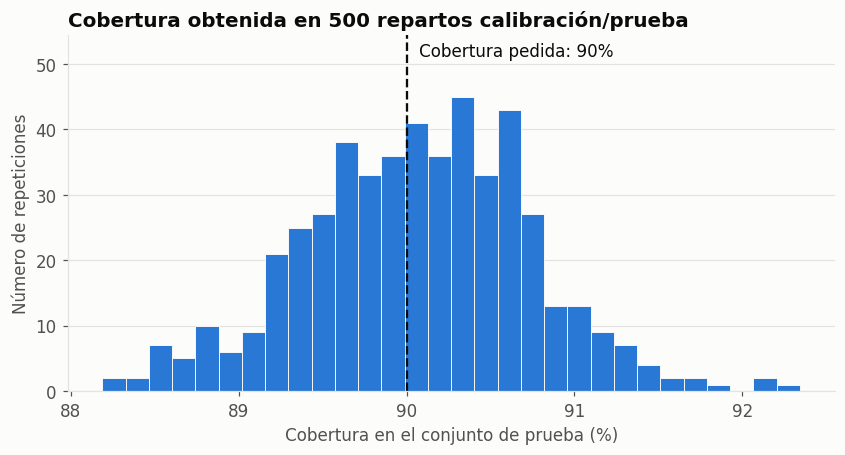

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(coberturas * 100, bins=30, color=AZUL, edgecolor=FONDO, linewidth=0.6)
ax.axvline((1 - ALPHA) * 100, color=TEXTO, linewidth=1.5, linestyle="--")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)     # espacio para la etiqueta sobre las barras
ax.annotate(f"Cobertura pedida: {1 - ALPHA:.0%}", xy=((1 - ALPHA) * 100, ax.get_ylim()[1] * 0.98),
            xytext=(8, 0), textcoords="offset points", va="top", color=TEXTO)
ax.set_title("Cobertura obtenida en 500 repartos calibración/prueba")
ax.set_xlabel("Cobertura en el conjunto de prueba (%)")
ax.set_ylabel("Número de repeticiones")
fig.savefig(FIG_DIR / "03_cobertura_repeticiones.png")
plt.show()

La cobertura se concentra alrededor del 90%: unas particiones dan un poco más y otras un poco menos, pero el promedio coincide con lo pedido. Esa es la garantía **marginal**.

## 8. Una limitación: el ancho es igual para todos

Con el puntaje $|y - \hat{y}|$ el intervalo es $\hat{y} \pm \hat{q}$ para cualquier vivienda. Pero el modelo no se equivoca igual en todas partes. Si separamos las casas de prueba en cuatro grupos según el precio predicho, la cobertura **no** es 90% en cada grupo.

In [25]:
grupos = ["25% más baratas", "Medio-bajo", "Medio-alto", "25% más caras"]
resultado["grupo"] = pd.qcut(resultado["prediccion"], 4, labels=grupos)

por_grupo = (resultado.assign(error=(resultado["valor_real"] - resultado["prediccion"]).abs())
             .groupby("grupo", observed=True)
             .agg(error_medio=("error", "mean"), cobertura=("cubierto", "mean")))
por_grupo["ancho_intervalo"] = 2 * q_hat
por_grupo["cobertura"] = por_grupo["cobertura"].map("{:.1%}".format)
por_grupo.round(1)

,error_medio,cobertura,ancho_intervalo
grupo,,,
25% más baratas,33.2,99.2%,295.8
Medio-bajo,43.7,96.1%,295.8
Medio-alto,61.5,92.6%,295.8
25% más caras,149.0,67.0%,295.8


Las casas baratas reciben un intervalo más ancho de lo necesario y las caras uno demasiado angosto. Aquí el efecto es más fuerte que en California porque los precios no están topados: unas pocas casas de varios millones tienen errores mucho mayores que el resto. El 90% se cumple **en promedio**, no dentro de cada grupo.

## 9. Extra: intervalos adaptativos con CQR

**Conformalized Quantile Regression** cambia dos cosas:

- En lugar de un modelo que predice la media, se entrenan dos modelos que predicen los cuantiles 5% y 95%. Eso ya da un intervalo de ancho variable, pero sin garantía.
- El puntaje pasa a ser cuánto se sale el valor real de ese intervalo: $s_i = \max(\hat{q}_{inf}(x_i) - y_i,\ y_i - \hat{q}_{sup}(x_i))$

El resto es idéntico: mismo conjunto de calibración, misma función `cuantil_conformal`.

Como modelos de cuantiles usamos gradient boosting (`HistGradientBoostingRegressor` con `loss="quantile"`). En la gráfica, la predicción del Random Forest aparece solo como referencia: el intervalo de CQR sale de los dos modelos de cuantiles, no de ella.

In [26]:
m_inf = HistGradientBoostingRegressor(loss="quantile", quantile=ALPHA / 2, random_state=SEED).fit(X_train, y_train)
m_sup = HistGradientBoostingRegressor(loss="quantile", quantile=1 - ALPHA / 2, random_state=SEED).fit(X_train, y_train)

# Intervalo de los modelos de cuantiles, sin calibrar
cobertura_sin_calibrar = np.mean((y_test >= m_inf.predict(X_test)) & (y_test <= m_sup.predict(X_test)))

# Calibración conformal
puntajes_cqr = np.maximum(m_inf.predict(X_cal) - y_cal, y_cal - m_sup.predict(X_cal)).to_numpy()
q_cqr = cuantil_conformal(puntajes_cqr, ALPHA)

res_cqr = pd.DataFrame({
    "valor_real": y_test.to_numpy(),
    "prediccion": pred_test,
    "inferior": m_inf.predict(X_test) - q_cqr,
    "superior": m_sup.predict(X_test) + q_cqr,
})
res_cqr["cubierto"] = res_cqr["valor_real"].between(res_cqr["inferior"], res_cqr["superior"])
res_cqr["ancho"] = res_cqr["superior"] - res_cqr["inferior"]
res_cqr["grupo"] = resultado["grupo"].to_numpy()

print(f"Cobertura de los cuantiles sin calibrar: {cobertura_sin_calibrar:.1%}")
print(f"Corrección conformal q̂:                 {q_cqr:+.1f} mil USD a cada lado")
print(f"Cobertura de CQR:                        {res_cqr['cubierto'].mean():.1%}")
print(f"Ancho del intervalo: de {res_cqr['ancho'].min():.0f} a {res_cqr['ancho'].max():.0f} mil USD "
      f"(promedio {res_cqr['ancho'].mean():.0f})")

c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1024, in __init__
    self._execute_child(args, executable, preexec_fn, close

Cobertura de los cuantiles sin calibrar: 84.0%
Corrección conformal q̂:                 +16.1 mil USD a cada lado
Cobertura de CQR:                        89.2%
Ancho del intervalo: de 60 a 3714 mil USD (promedio 306)


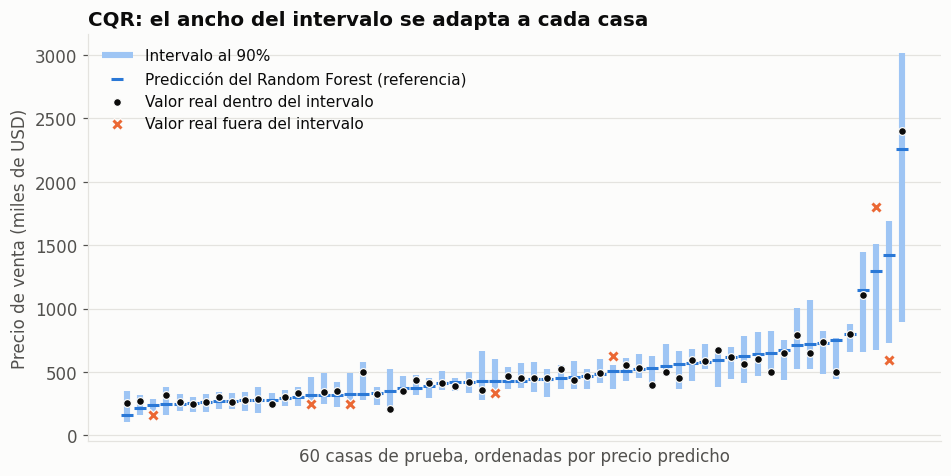

En esta muestra: 53 de 60 valores reales dentro del intervalo


In [27]:
grafica_intervalos(res_cqr, "CQR: el ancho del intervalo se adapta a cada casa",
                   "04_intervalos_cqr.png", etiqueta_pred="Predicción del Random Forest (referencia)")

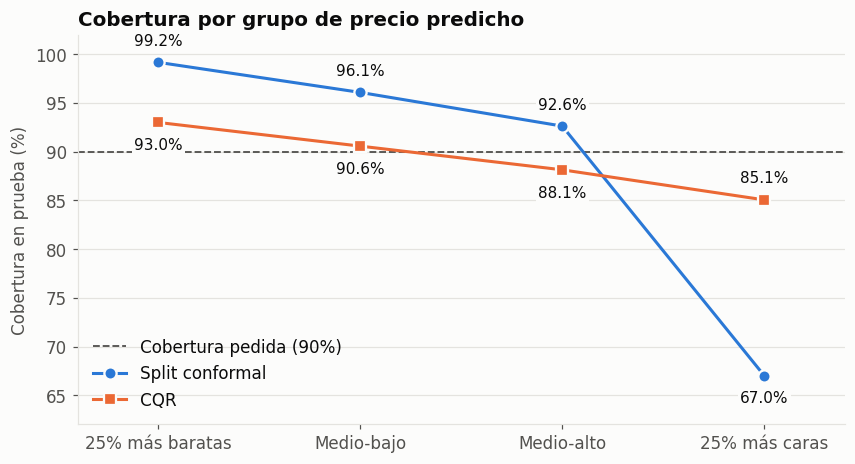

,Split conformal,CQR
grupo,,
25% más baratas,99.2,93.0
Medio-bajo,96.1,90.6
Medio-alto,92.6,88.1
25% más caras,67.0,85.1


In [28]:
comparacion = pd.DataFrame({
    "Split conformal": resultado.groupby("grupo", observed=True)["cubierto"].mean() * 100,
    "CQR": res_cqr.groupby("grupo", observed=True)["cubierto"].mean() * 100,
}).reindex(grupos)

fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(comparacion))
ax.axhline((1 - ALPHA) * 100, color=TEXTO_2, linewidth=1.2, linestyle="--",
           label=f"Cobertura pedida ({1 - ALPHA:.0%})")
estilos = {"Split conformal": (AZUL, "o"), "CQR": (NARANJA, "s")}
for nombre, (color, marcador) in estilos.items():
    otro = comparacion.drop(columns=nombre).iloc[:, 0]
    ax.plot(x, comparacion[nombre], color=color, marker=marcador, markersize=8, linewidth=2,
            markeredgecolor=FONDO, markeredgewidth=1.5, label=nombre, zorder=3)
    for xi, v, v_otro in zip(x, comparacion[nombre], otro):
        dy = 14 if v >= v_otro else -15      # la serie más alta se rotula arriba, la otra abajo
        ax.annotate(f"{v:.1f}%", (xi, v), xytext=(0, dy), textcoords="offset points",
                    ha="center", va="center", fontsize=10, color=TEXTO, zorder=4,
                    bbox=dict(facecolor=FONDO, edgecolor="none", pad=1.5))
ax.set_xticks(x, comparacion.index)
ax.set_xlim(-0.4, len(x) - 0.6)
ax.set_ylim(min(70, comparacion.min().min() - 5), 102)
ax.set_title("Cobertura por grupo de precio predicho")
ax.set_ylabel("Cobertura en prueba (%)")
ax.legend(loc="lower left")
fig.savefig(FIG_DIR / "05_cobertura_por_grupo.png")
plt.show()

comparacion.round(1)

## 10. Resumen

In [29]:
resumen = pd.DataFrame([
    {"método": "Ingenuo (errores de entrenamiento)", "cobertura": cobertura_ingenua,
     "ancho promedio": 2 * margen_ingenuo, "ancho variable": "no"},
    {"método": "Split conformal", "cobertura": resultado["cubierto"].mean(),
     "ancho promedio": 2 * q_hat, "ancho variable": "no"},
    {"método": "CQR", "cobertura": res_cqr["cubierto"].mean(),
     "ancho promedio": res_cqr["ancho"].mean(), "ancho variable": "sí"},
])
resumen["cobertura"] = resumen["cobertura"].map("{:.1%}".format)
resumen["ancho promedio"] = resumen["ancho promedio"].round(1)
print(f"Cobertura pedida: {1 - ALPHA:.0%}")
resumen.set_index("método")

Cobertura pedida: 90%


,cobertura,ancho promedio,ancho variable
método,,,
Ingenuo (errores de entrenamiento),63.4%,113.4,no
Split conformal,88.7%,295.8,no
CQR,89.2%,306.1,sí


**Qué muestra el experimento**

- Sin calibración, un intervalo que promete 90% no lo cumple.
- Split conformal alcanza la cobertura pedida **en promedio** con muy poco código y sin tocar el modelo. Una partición concreta puede quedar un poco por encima o por debajo, como pasó aquí.
- Limpiar los datos (ventas repetidas, registros imposibles) es parte de que la garantía sea válida: calibración, prueba y datos nuevos deben venir del mismo proceso.
- La garantía es **marginal**: se cumple en promedio, no dentro de cada subgrupo.
- La validez viene del método; qué tan útiles son los intervalos depende del modelo y del puntaje elegido. CQR usa la misma calibración y reparte mejor el ancho.

**Supuesto.** Todo depende de que los datos de calibración y los datos nuevos sean intercambiables. Aquí se cumple porque la partición es aleatoria y quitamos las ventas repetidas; con datos de otra región u otra época, la garantía ya no aplica.